# Экзамен 2026. Новиков Сергей, ИИФТ'28

# Задача 1

In [18]:
%pip -q install openpyxl

import pandas as pd
from IPython.display import display
from google.colab import files

In [7]:
uploaded = files.upload()

Saving NHL-playoffs-2026.xlsx to NHL-playoffs-2026 (1).xlsx


In [19]:
events = pd.read_excel(
    "NHL-playoffs-2026.xlsx",
    sheet_name=0,
    index_col=0,
    engine="openpyxl"
)

print("Размер таблицы:", events.shape)

Размер таблицы: (29710, 38)


In [20]:
# Пример из условия
display(events.iloc[:10, [2, 3, 4, 9, 12]])

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


In [21]:
assert events.shape == (29710, 38), "Размер таблицы отличается от ожидаемого."

events.info()

print("\nЧисло матчей:", events["Game ID"].nunique())

<class 'pandas.core.frame.DataFrame'>
Index: 29710 entries, 0 to 29709
Data columns (total 38 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Dataset                              29710 non-null  object 
 1   Game ID                              29710 non-null  int64  
 2   Date                                 29710 non-null  object 
 3   Away Team                            29710 non-null  object 
 4   Home Team                            29710 non-null  object 
 5   Cumulated Away Score                 29710 non-null  int64  
 6   Cumulated Home Score                 29710 non-null  int64  
 7   Period                               29710 non-null  int64  
 8   Elapsed Time                         29710 non-null  object 
 9   Remaining Time                       29710 non-null  object 
 10  Play ID                              29710 non-null  int64  
 11  Play Length                      

### Вывод

Данные загружены в таблицу pandas `events`. Она содержит 29 710 событий
и 38 признаков. В наборе представлены 82 матча.

Каждая строка соответствует отдельному событию, поэтому число строк
не равно числу матчей. Первый столбец исходного Excel содержит номера
строк и использован как индекс.

Пропуски сохранены: некоторые поля неприменимы к отдельным типам событий.
Например, событие начала периода не содержит информации об игроке,
совершившем бросок.

## Задача 2


In [22]:
# Группируем события по идентификатору матча. Для каждой группы рассчитываем одну строку сводной таблицы.
games = events.groupby("Game ID", sort=True).agg(**{
    "Date": ("Date", "first"),
    "Away Team": ("Away Team", "first"),
    "Home Team": ("Home Team", "first"),
    "Away Score": ("Cumulated Away Score", "max"),
    "Home Score": ("Cumulated Home Score", "max"),
    "Last Period": ("Period", "max"),
})

games["Overtimes"] = (
    (games["Last Period"] - 3)
    .clip(lower=0)
    .astype(int)
)

def format_outcome(overtimes):
    if overtimes == 0:
        return "Final"
    if overtimes == 1:
        return "Final/OT"
    return f"Final/{overtimes}OT"

games["Outcome"] = games["Overtimes"].map(format_outcome)

games = games[[
    "Date",
    "Away Team",
    "Home Team",
    "Away Score",
    "Home Score",
    "Overtimes",
    "Outcome",
]]

display(games.head())
display(games.tail())

,Date,Away Team,Home Team,Away Score,Home Score,Overtimes,Outcome
Game ID,,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,0,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,0,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,0,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,0,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,1,Final/OT


,Date,Away Team,Home Team,Away Score,Home Score,Overtimes,Outcome
Game ID,,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,1,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,2,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,0,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,0,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,0,Final


In [24]:
# проверяем, что каждый матч представлен один раз, ничьих нет, а рассчитанные счета совпадают со счетами в событиях окончания матчей.

assert len(games) == events["Game ID"].nunique() == 82
assert games.index.is_unique
assert (games["Away Score"] != games["Home Score"]).all()

final_events = events.loc[
    events["Play Type"].eq("game-end")
].set_index("Game ID")

assert final_events.index.is_unique
assert set(final_events.index) == set(games.index)

assert games["Away Score"].eq(
    final_events["Cumulated Away Score"].reindex(games.index)
).all()

assert games["Home Score"].eq(
    final_events["Cumulated Home Score"].reindex(games.index)
).all()

print("Все проверки пройдены.")
print("Размер таблицы games:", games.shape)

overtime_counts = (
    games["Overtimes"]
    .value_counts()
    .sort_index()
    .rename_axis("Число овертаймов")
    .rename("Число матчей")
    .to_frame()
)

display(overtime_counts)

Все проверки пройдены.
Размер таблицы games: (82, 7)


,Число матчей
Число овертаймов,
0,60
1,18
2,4


### Метод расчёта

События сгруппированы по идентификатору матча `Game ID`.
Внутри каждого матча дата и названия команд постоянны,
поэтому для этих полей выбраны первые значения.
Итоговый счёт определён как максимум накопленного числа голов
каждой команды. Полученные значения проверены по событиям
окончания матчей (`game-end`).

Число овертаймов рассчитано как максимальный номер периода
минус три, но не менее нуля.

### Вывод

Теперь у нас есть сводная таблица `games`, она содержит 82 строки и 7 столбцов.
Для каждого матча сохранены дата, команды, итоговый счёт,
число овертаймов и текстовое обозначение исхода.
Идентификатор `Game ID` используется как индекс таблицы.

В основное время завершились 60 матчей, в первом овертайме — 18,
во втором — 4. Дополнительное время потребовалось в 22 из 82 матчей,
то есть примерно в 26,8% случаев. Максимальное число овертаймов — два.

Числовой столбец `Overtimes` позволяет анализировать количество
овертаймов, а `Outcome` соответствует обозначениям из условия:
`Final`, `Final/OT`, `Final/2OT`.

## Задача 3

Примечанеи: Порядок команд и счёта: хозяева — гости.

In [27]:
def gameInfo(gameId):
    """Возвращает описание матча по его идентификатору в таблице games."""

    game = games.loc[gameId]

    date = pd.Timestamp(game["Date"]).strftime("%Y-%m-%d")

    return (
        f"{game['Home Team']} - {game['Away Team']} "
        f"({game['Home Score']} - {game['Away Score']}, "
        f"{game['Outcome']}, {date})"
    )

In [28]:
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


### Пояснение

Функция `gameInfo(gameId)` использует таблицу `games`, созданную
в задаче 2. Выражение `games.loc[gameId]` выбирает строку
по идентификатору матча, который является индексом таблицы.
В описании сначала указаны хозяева и их счёт, затем гости и их счёт.
Дата представлена в формате `YYYY-MM-DD`.

Функция возвращает строку с помощью `return`.
Это позволяет использовать результат не только для вывода на экран,
но и при составлении списков матчей или заголовков графиков.
В примерах строка выводится на экран с помощью `print()`.

### Вывод

Создана функция для получения краткого описания матча
по его идентификатору. Проверка на минимальном и максимальном
`Game ID` воспроизводит оба примера из условия.

## Задача 4

Для расчёта используем итоговые счета гостей и хозяев
из таблицы `games`.

In [29]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
display(games[["Away Score", "Home Score", "Total Score"]].head())

,Away Score,Home Score,Total Score
Game ID,,,
2025030111,3,4,7
2025030112,4,2,6
2025030113,3,1,4
2025030114,6,1,7
2025030115,2,1,3


In [30]:
total_score_stats = games["Total Score"].describe()

display(total_score_stats.round(3))

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


### Вывод

В таблицу `games` добавлен столбец `Total Score`, содержащий общее
число голов в каждом матче. Среднее и медиана близки к 6 голам,
при этом результативность отдельных матчей варьируется от 1 до 15 голов.

По описательным статистикам нельзя однозначно определить форму
распределения. Для её изучения в следующей задаче построим график.

## Задача 5
Количество голов — дискретная величина. Поэтому используем
`seaborn.countplot()`: каждый столбец показывает частоту
конкретного значения.

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

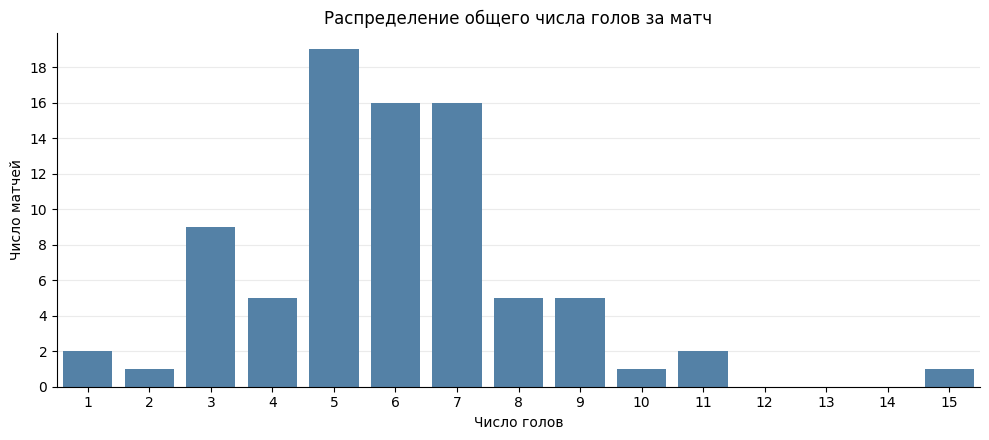

In [32]:
goal_order = list(range(
    int(games["Total Score"].min()),
    int(games["Total Score"].max()) + 1
))

fig, ax = plt.subplots(figsize=(10, 4.5))

sns.countplot(
    data=games,
    x="Total Score",
    order=goal_order,
    color="steelblue",
    ax=ax
)

ax.set_title("Распределение общего числа голов за матч")
ax.set_xlabel("Число голов")
ax.set_ylabel("Число матчей")

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

In [33]:
goal_counts = (
    games["Total Score"]
    .value_counts()
    .reindex(goal_order, fill_value=0)
    .rename_axis("Число голов")
    .rename("Число матчей")
    .to_frame()
)

display(goal_counts)

print("Всего матчей:", goal_counts["Число матчей"].sum())

,Число матчей
Число голов,
1,2
2,1
3,9
4,5
5,19
6,16
7,16
8,5
9,5


Всего матчей: 82


### Интерпретация графика
Наиболее часто встречались матчи с 5 голами — 19 из 82 матчей,
или около 23,2%. Следовательно, мода распределения равна 5.
Матчи с 6 и 7 голами встречались по 16 раз. В диапазоне от 5 до 7 голов включительно завершился 51 матч, то есть около 62,2% всех игр. Здесь сосредоточена основная масса наблюдений.

Матчи с высокой результативностью встречались редко:
10 и 15 голов зафиксированы по одному разу, 11 голов — дважды.
Матчей с 12, 13 и 14 голами в данных нет. Высокие значения образуют правый хвост распределения. Матч с 15 голами заметно удалён от основной массы наблюдений и не является типичным для этой выборки.

### Вывод

Чаще всего команды совместно забивали от 5 до 7 голов за матч.
Наиболее распространённое значение — 5 голов.
График дополняет описательные статистики: он показывает
концентрацию матчей около 5–7 голов и редкие случаи высокой
результативности. Причины различий между матчами по этому
графику определить нельзя.

## Задача 6

Результативность измеряем общим числом голов обеих команд —
показателем `Total Score`.

In [35]:
min_total_score = games["Total Score"].min()
max_total_score = games["Total Score"].max()

least_scoring_ids = games.index[
    games["Total Score"].eq(min_total_score)
]

most_scoring_ids = games.index[
    games["Total Score"].eq(max_total_score)
]

least_scoring_games = [
    gameInfo(game_id) for game_id in least_scoring_ids
]

most_scoring_games = [
    gameInfo(game_id) for game_id in most_scoring_ids
]

In [36]:
print(f"Самые нерезультативные матчи: {min_total_score} гол за матч")

for match in least_scoring_games:
    print(match)

print(f"\nСамые результативные матчи: {max_total_score} голов за матч")

for match in most_scoring_games:
    print(match)

Самые нерезультативные матчи: 1 гол за матч
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)

Самые результативные матчи: 15 голов за матч
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


### Вывод

Минимальная результативность составила 1 гол. Таких матчей два:

- Montréal Canadiens — Tampa Bay Lightning: 0:1,
  первый овертайм, 1 мая 2026 года.
- Philadelphia Flyers — Pittsburgh Penguins: 1:0,
  первый овертайм, 29 апреля 2026 года.

Максимальная результативность составила 15 голов.
Такой матч один: Colorado Avalanche — Minnesota Wild,
9:6, основное время, 3 мая 2026 года.

Оба самых нерезультативных матча завершились в первом овертайме,
а самый результативный — в основное время. Эти отдельные наблюдения
не позволяют сделать общий вывод о связи овертаймов с результативностью.

## Задача 7


In [37]:
player_columns = (
    [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
    + [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
    + ["Away Team's Goalie", "Home Team's Goalie"]
)

players_long = events[["Game ID"] + player_columns].melt(
    id_vars="Game ID",
    value_vars=player_columns,
    var_name="Source Column",
    value_name="Player"
)

players_long = players_long.dropna(subset=["Player"])

display(players_long.head())

,Game ID,Source Column,Player
0,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
1,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
2,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
3,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
4,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson


In [40]:
player_counts = players_long.groupby("Game ID")["Player"].nunique()
games["Player Count"] = player_counts.reindex(games.index)
assert games["Player Count"].notna().all()
games["Player Count"] = games["Player Count"].astype(int)
max_player_count = games["Player Count"].max()
most_players_games = games.loc[
    games["Player Count"].eq(max_player_count),
    ["Player Count"]
].copy()

most_players_games.insert(
    0,
    "Game Info",
    [gameInfo(game_id) for game_id in most_players_games.index]
)

In [41]:
print("Максимальное число игроков в одном матче:", max_player_count)

with pd.option_context("display.max_colwidth", None):
    display(most_players_games)

Максимальное число игроков в одном матче: 40


,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40


### Метод расчёта

Использованы шесть столбцов игроков гостей, шесть столбцов игроков
хозяев и два отдельных столбца вратарей.
Метод `melt()` объединяет имена из этих столбцов в один столбец.
После удаления пропусков метод `nunique()` считает уникальных
игроков внутри каждого матча.

Игрок учитывается один раз, даже если он присутствует во многих
событиях или одновременно указан в столбце состава и столбце вратаря.
Игроки идентифицируются по именам, поскольку отдельных идентификаторов
игроков в предложенной таблице нет.

### Вывод

Максимальное число участвовавших игроков — 40.
Оно зафиксировано в матче Montréal Canadiens — Buffalo Sabres,
завершившемся со счётом 3:8 в основное время 16 мая 2026 года.
В этом матче у каждой команды зафиксировано по 20 игроков,
включая по двух вратарей.

Количество игроков рассчитано для всех матчей и сохранено
в столбце `Player Count` таблицы `games`.

В примере указано 41 игрока. Расхождение объясняется тем, что в составе матча
есть пустой слот (NaN), который при подсчёте без исключения пропусков считается
отдельным «игроком». В расчёте учитываются только реальные имена, поэтому результат 40.

## Задача 8

- `shot-on-goal` — бросок в створ, отражённый вратарём;
- `goal` — гол;
- `missed-shot` — бросок мимо ворот.

Заблокированные броски в этой задаче не рассматриваем.

In [42]:
import numpy as np

shot_mask = events["Play Type"].isin([
    "shot-on-goal", "goal", "missed-shot"
])

shots = events.loc[shot_mask].copy()

required_columns = [
    "Team Making the Play",
    "Home Team",
    "Away Team",
    "Home Team's Defending Side",
    "X Coordinate on the Ice Rink",
    "Y Coordinate on the Ice Rink"
]

assert shots[required_columns].notna().all().all()

assert shots["Home Team's Defending Side"].isin(["left", "right"]).all()

assert (
    shots["Team Making the Play"].eq(shots["Home Team"])
    | shots["Team Making the Play"].eq(shots["Away Team"])
).all()

print("Количество рассматриваемых бросков:", len(shots))

Количество рассматриваемых бросков: 7266


In [43]:
# True, если бросают хозяева; False, если гости.
home_shot = shots["Team Making the Play"].eq(shots["Home Team"])

# True, если хозяева защищают левые ворота.
home_defends_left = shots["Home Team's Defending Side"].eq("left")

# Правые ворота атакуются в двух случаях:
# 1) бросают хозяева, защищающие левые ворота;
# 2) бросают гости, а хозяева защищают правые ворота.
attacks_right = (
    (home_shot & home_defends_left)
    | (~home_shot & ~home_defends_left)
)

# Координата X атакуемых ворот.
shots["Target Goal X"] = np.where(attacks_right, 89.0, -89.0)

# Расстояние до ближайшей точки створа

Ближайшую координату Y на створе определяем следующим образом:

- если Y броска меньше −3, выбираем нижний край створа: −3;
- если Y находится между −3 и 3, оставляем исходное значение;
- если Y больше 3, выбираем верхний край створа: 3.

Эту операцию выполняет `clip(-3, 3)`.

Затем рассчитываем обычное евклидово расстояние между точкой
броска и найденной точкой створа. Если Y броска находится
между −3 и 3, расстояние равно модулю разности координат X.

In [45]:
nearest_goal_y = shots["Y Coordinate on the Ice Rink"].clip(-3, 3)

dx = shots["X Coordinate on the Ice Rink"] - shots["Target Goal X"]

dy = shots["Y Coordinate on the Ice Rink"] - nearest_goal_y

shots["Shot Length"] = np.hypot(dx, dy)

events["Shot Length"] = np.nan

events.loc[shots.index, "Shot Length"] = shots["Shot Length"]

In [46]:
# Проверяем количество, отсутствие пропусков и допустимость расстояний.
assert len(shots) == 7266
assert np.isfinite(shots["Shot Length"]).all()
assert shots["Shot Length"].ge(0).all()

assert events.loc[~shot_mask, "Shot Length"].isna().all()

shot_lengths = events.loc[
    shot_mask,
    ["Game ID", "Play Type", "Shot Length"]
]

with pd.option_context("display.float_format", "{:.3f}".format):
    display(shot_lengths)

print("Количество рассчитанных расстояний:", len(shot_lengths))

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Количество рассчитанных расстояний: 7266


### Вывод

Расстояние до ближайшей точки створа рассчитано для 7 266
незаблокированных бросков, включая голы. Результаты сохранены
в столбце `Shot Length` таблицы `events`.

При расчёте учтены ширина створа и направление атаки.
Атакуемые ворота определены по команде, выполняющей бросок,
и стороне защиты хозяев для соответствующего события. Дополнительно менять координаты по номеру периода не требуется: направление атаки уже определено через поле стороны защиты.

Для первого броска расстояние составляет примерно 12,207 фута,
для второго — 12 футов. Результаты соответствуют примеру из условия.
Для остальных типов событий в столбце `Shot Length` оставлены
пропуски. Расстояния сохранены без округления, чтобы использовать
их в последующих расчётах.

## Задача 9

К точным броскам относим `shot-on-goal` и `goal`,
к неточным — `missed-shot`. Заблокированные броски исключаем.

In [98]:
shots_comparison = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"]),
    ["Play Type", "Shot Length"]
].copy()

shots_comparison["Shot"] = shots_comparison["Play Type"].map({
    "shot-on-goal": "Точный",
    "goal": "Точный",
    "missed-shot": "Мимо"
})

assert shots_comparison[["Shot", "Shot Length"]].notna().all().all()

shot_summary = shots_comparison.groupby("Shot")["Shot Length"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Max="max"
)

display(shot_summary.round(3))

,Count,Mean,Median,Max
Shot,,,,
Мимо,2643,34.014,32.249,185.068
Точный,4623,36.207,31.828,188.215


### Как сравниваем распределения

В функции `seaborn.displot()` используем:

- `stat="density"` — показываем плотность вместо количества бросков;
- `common_norm=False` — нормируем каждую группу отдельно;
- одинаковые интервалы шириной 5 футов для обеих групп.

Площадь каждой гистограммы равна единице. Поэтому большее
количество точных бросков само по себе не увеличивает высоту
их гистограммы. Высота столбца показывает плотность. Чтобы получить долю бросков
своей группы в интервале, нужно умножить высоту на ширину интервала.

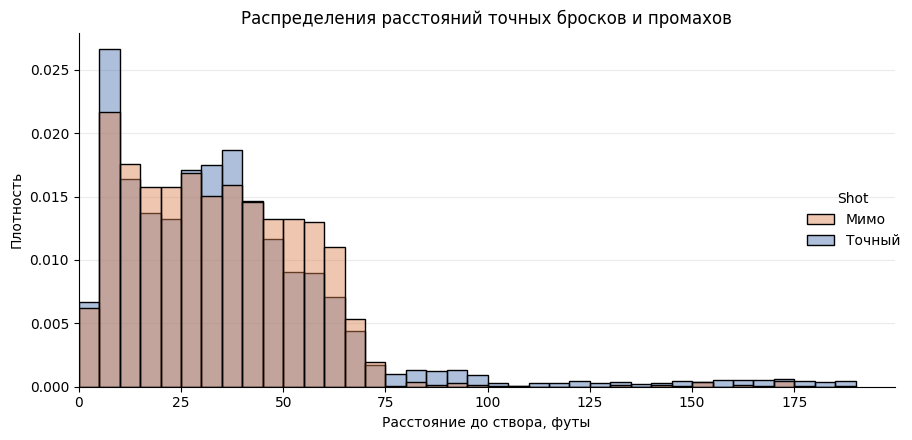

In [99]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

max_length = shots_comparison["Shot Length"].max()

bin_edges = np.arange(
    0,
    np.ceil(max_length / 5) * 5 + 1,
    5
)

g = sns.displot(
    data=shots_comparison,
    x="Shot Length",
    hue="Shot",
    hue_order=["Мимо", "Точный"],
    palette={"Мимо": "#DD8452", "Точный": "#4C72B0"},
    kind="hist",
    bins=bin_edges,
    stat="density",
    common_norm=False,
    multiple="layer",
    alpha=0.45,
    height=4.5,
    aspect=1.8
)

g.set_axis_labels("Расстояние до створа, футы", "Плотность")
g.ax.set_title("Распределения расстояний точных бросков и промахов")
g.ax.set_xlim(left=0)

g.ax.set_axisbelow(True)
g.ax.grid(axis="y", alpha=0.25)
g.fig.tight_layout()
plt.show()

### Интерпретация графика

В данных представлены 4 623 точных броска и 2 643 промаха.
Благодаря отдельной нормировке сравнение распределений учитывает
разный размер групп.

Распределения существенно перекрываются. В обеих группах основная
масса бросков приходится на расстояния примерно до 70 футов: до 70 футов
находятся 92,8% точных бросков и 97,6% промахов.
Медианы близки: 31,828 фута для точных бросков и 32,249 фута
для промахов.

При этом у точных бросков заметнее длинный хвост.
Среднее расстояние точного броска составляет 36,207 фута,
а промаха — 34,014 фута. Поэтому нельзя утверждать,
что точные броски в этой выборке в среднем выполнялись
с меньшего расстояния.

In [100]:
far_threshold = 75

share_table = pd.DataFrame({
    "Бросков всего": shots_comparison.groupby("Shot").size(),
    "Дальше 75 футов": shots_comparison.loc[
        shots_comparison["Shot Length"].gt(far_threshold)
    ].groupby("Shot").size(),
})
share_table["Доля дальше 75 футов, %"] = (
    100 * share_table["Дальше 75 футов"] / share_table["Бросков всего"]
).round(2)

assert share_table["Бросков всего"].sum() == 7266
display(share_table)

,Бросков всего,Дальше 75 футов,"Доля дальше 75 футов, %"
Shot,,,
Мимо,2643,37,1.40
Точный,4623,292,6.32


In [101]:
far_accurate = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal"])
    & events["Shot Length"].gt(far_threshold)
].copy()

opp_goalie = np.where(
    far_accurate["Team Making the Play"].eq(far_accurate["Home Team"]),
    far_accurate["Away Team's Goalie"],
    far_accurate["Home Team's Goalie"],
)
empty_net = pd.Series(opp_goalie, index=far_accurate.index).isna()

print("Точных бросков дальше 75 футов:", len(far_accurate))
print("  из них голов:", int((far_accurate["Play Type"] == "goal").sum()))
print("  из них в пустые ворота:", int(empty_net.sum()))

Точных бросков дальше 75 футов: 292
  из них голов: 22
  из них в пустые ворота: 3


In [103]:
shots_all = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"])
].copy()

home_shot = shots_all["Team Making the Play"].eq(shots_all["Home Team"])
home_defends_left = shots_all["Home Team's Defending Side"].eq("left")
attacks_right = (home_shot & home_defends_left) | (~home_shot & ~home_defends_left)

attack_sign = np.where(attacks_right, 1, -1)
shots_all["Own Half"] = (shots_all["X Coordinate on the Ice Rink"] * attack_sign) < 0
shots_all["Accurate"] = shots_all["Play Type"].isin(["shot-on-goal", "goal"])

own_half_table = pd.DataFrame({
    "Бросков всего": shots_all.groupby("Accurate").size(),
    "С собственной половины": shots_all[shots_all["Own Half"]].groupby("Accurate").size(),
})
own_half_table.index = ["Мимо", "Точный"]
own_half_table["Доля от группы, %"] = (
    100 * own_half_table["С собственной половины"] / own_half_table["Бросков всего"]
).round(2)

assert own_half_table["Бросков всего"].sum() == 7266
assert own_half_table["С собственной половины"].sum() == shots_all["Own Half"].sum()
display(own_half_table)

print("Доля точных среди бросков с собственной половины:",
      round(shots_all.loc[shots_all["Own Half"], "Accurate"].mean(), 3))
print("Доля точных среди всех бросков:", round(shots_all["Accurate"].mean(), 3))

,Бросков всего,С собственной половины,"Доля от группы, %"
Мимо,2643,27,1.02
Точный,4623,185,4.00


Доля точных среди бросков с собственной половины: 0.873
Доля точных среди всех бросков: 0.636


### Почему у точных бросков длинный хвост со своей половины?

Дальше 75 футов находятся 6,3% точных бросков (292 из 4 623) и 1,4% промахов
(37 из 2 643).

Если смотреть на собственную половину площадки, то с неё выполнено 185 точных
бросков (4,0% от всех точных) и 27 промахов (1,0% от всех промахов). Из бросков
с собственной половины в створ попали 87%, а по всем броскам этот показатель — 64%.
Значит, дальний бросок с собственной половины в большинстве случаев оказывается точным.

Гипотеза о пустых воротах это не объясняет: из 292 дальних точных бросков в пустые
ворота попали только 3.

Данные не позволяют различить возможные причины:
- дальний бросок, направленный в створ при выходе из своей зоны, почти всегда
  доходит до вратаря и регистрируется как точный;
- дальние промахи могут фиксироваться реже, чем дальние броски в створ, поэтому
  доля точных среди записанных дальних бросков выше. Это гипотеза о регистрации
  событий, и проверить её по имеющимся полям нельзя.

### Вывод

Распределения расстояний точных бросков и промахов похожи в основной части,
но у точных бросков сильнее выражен длинный хвост.

Расстояние само по себе не определяет исход броска.
Эти гистограммы показывают распределение расстояний внутри групп,
а не вероятность попадания в створ при заданном расстоянии.

## Задача 10

Точные броски включают:
- `shot-on-goal` — броски, отражённые вратарём;
- `goal` — голы.
Все незаблокированные броски дополнительно включают
`missed-shot` — промахи. Заблокированные броски исключаем.

Доля точных бросков =
(shot-on-goal + goal) / (shot-on-goal + goal + missed-shot).
Результат сохраним в таблице `numshots` с составным индексом:
идентификатор матча и команда, выполняющая бросок.

In [49]:
team_shots = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"]),
    ["Game ID", "Team Making the Play", "Play Type"]
].copy()

team_shots["On Goal"] = team_shots["Play Type"].isin([
    "shot-on-goal", "goal"
])

numshots = team_shots.groupby(
    ["Game ID", "Team Making the Play"],
    sort=True
).agg(
    **{
        "Shots on Goal": ("On Goal", "sum"),
        "Unblocked Shots": ("On Goal", "size")
    }
)

numshots["Missed Shots"] = (
    numshots["Unblocked Shots"] - numshots["Shots on Goal"]
)

numshots["Share of Shots on Goal"] = (
    numshots["Shots on Goal"] / numshots["Unblocked Shots"]
)

numshots = numshots[[
    "Shots on Goal",
    "Missed Shots",
    "Unblocked Shots",
    "Share of Shots on Goal"
]]

In [50]:
assert len(numshots) == 2 * len(games) == 164
assert numshots.groupby(level="Game ID").size().eq(2).all()

assert numshots["Unblocked Shots"].gt(0).all()
assert numshots["Share of Shots on Goal"].between(0, 1).all()

for game_id, game in games.iterrows():
    actual_teams = set(numshots.loc[game_id].index)
    expected_teams = {game["Away Team"], game["Home Team"]}
    assert actual_teams == expected_teams

assert numshots["Unblocked Shots"].sum() == 7266
assert numshots["Shots on Goal"].sum() == 4623
assert numshots["Missed Shots"].sum() == 2643

with pd.option_context("display.float_format", "{:.3f}".format):
    display(numshots["Share of Shots on Goal"])

print("Количество пар «матч — команда»:", len(numshots))

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Количество пар «матч — команда»: 164


In [51]:
with pd.option_context("display.float_format", "{:.3f}".format):
    display(numshots.head(6))

display(
    numshots["Share of Shots on Goal"].describe().round(3)
)

# Общая доля по всем броскам турнира.
overall_on_goal_share = (
    numshots["Shots on Goal"].sum()
    / numshots["Unblocked Shots"].sum()
)

print(f"Общая доля точных бросков: {overall_on_goal_share:.2%}")

Shots on Goal  Missed Shots  Unblocked Shots  \
Game ID    Team Making the Play                                                 
2025030111 Boston Bruins                    20            12               32   
           Buffalo Sabres                   38            18               56   
2025030112 Boston Bruins                    27            17               44   
           Buffalo Sabres                   35            20               55   
2025030113 Boston Bruins                    25            11               36   
           Buffalo Sabres                   30            14               44   

                                 Share of Shots on Goal  
Game ID    Team Making the Play                          
2025030111 Boston Bruins                          0.625  
           Buffalo Sabres                         0.679  
2025030112 Boston Bruins                          0.614  
           Buffalo Sabres                         0.636  
2025030113 Boston Bruins                          0.694  
           Buffalo Sabres                         0.682

,Share of Shots on Goal
count,164.000
mean,0.639
std,0.085
min,0.353
25%,0.583
50%,0.639
75%,0.689
max,0.860


Общая доля точных бросков: 63.63%


### Вывод
Около 64% незаблокированных бросков достигали створа.
Показатель характеризует попадание в створ, а не долю бросков,
завершившихся голом. По нему нельзя однозначно оценить качество
атаки или вероятность победы: он не учитывает заблокированные
броски, опасность моментов и реализацию в голы.

Таблица `numshots` позволяет в следующей задаче сравнить
средние доли точных бросков между командами.

## Задача 11

In [52]:
avgnumshots = (
    numshots["Share of Shots on Goal"]
    .groupby(level="Team Making the Play")
    .mean()
)

assert len(avgnumshots) == 16
assert avgnumshots.between(0, 1).all()

top5_accuracy = avgnumshots.nlargest(5)

bottom5_accuracy = avgnumshots.nsmallest(5)

In [53]:
print("Пять команд с самыми высокими средними долями:")

with pd.option_context("display.float_format", "{:.3f}".format):
    display(top5_accuracy)

print("Пять команд с самыми низкими средними долями:")

with pd.option_context("display.float_format", "{:.3f}".format):
    display(bottom5_accuracy)

Пять команд с самыми высокими средними долями:


,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653


Пять команд с самыми низкими средними долями:


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


In [54]:
team_game_counts = (
    numshots.groupby(level="Team Making the Play")
    .size()
    .rename("Games Played")
)

accuracy_summary = pd.concat(
    [avgnumshots, team_game_counts],
    axis=1
).sort_values(
    "Share of Shots on Goal",
    ascending=False
)

with pd.option_context("display.float_format", "{:.3f}".format):
    display(accuracy_summary)

,Share of Shots on Goal,Games Played
Team Making the Play,,
Edmonton Oilers,0.706,6
Philadelphia Flyers,0.684,10
Dallas Stars,0.670,6
Minnesota Wild,0.656,11
Colorado Avalanche,0.653,13
Anaheim Ducks,0.649,12
Montréal Canadiens,0.644,19
Los Angeles Kings,0.642,4
Boston Bruins,0.638,6


### Ограничения сравнения

Команды провели разное число матчей. Например, средние
Edmonton Oilers и Pittsburgh Penguins рассчитаны по 6 матчам,
а Vegas Golden Knights — по 22 матчам.
Поэтому объём данных для оценки средних различается.
Полученный рейтинг сам по себе не доказывает статистическую
значимость различий.
Доля точных бросков характеризует попадание в створ.
Она не учитывает опасность бросков, их реализацию в голы
и общее число атакующих попыток.

### Вывод

Edmonton Oilers имеют самую высокую, а Pittsburgh Penguins —
самую низкую среднюю долю точных бросков за матч
в рассматриваемом наборе данных.

Рейтинг описывает точность незаблокированных бросков.
Его нельзя напрямую интерпретировать как рейтинг общей силы команд.

## Задача 12


In [55]:
goal_counts = (
    events.loc[events["Play Type"].eq("goal")]
    .groupby(["Game ID", "Team Making the Play"])
    .size()
)

shots_by_game = numshots[["Shots on Goal"]].rename(
    columns={"Shots on Goal": "Shot"}
).copy()

shots_by_game["Goal"] = goal_counts.reindex(
    shots_by_game.index,
    fill_value=0
).astype(int)

avgshots = (
    shots_by_game
    .groupby(level="Team Making the Play")[["Shot", "Goal"]]
    .mean()
)

with pd.option_context("display.float_format", "{:.3f}".format):
    display(avgshots)

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


In [56]:
assert len(shots_by_game) == 164
assert len(avgshots) == 16
assert avgshots.notna().all().all()

assert shots_by_game["Shot"].ge(shots_by_game["Goal"]).all()

assert shots_by_game["Shot"].sum() == 4623
assert (
    shots_by_game["Goal"].sum()
    == events["Play Type"].eq("goal").sum()
    == 486
)

away_goals = games.reset_index()[
    ["Game ID", "Away Team", "Away Score"]
].rename(columns={
    "Away Team": "Team Making the Play",
    "Away Score": "Goal"
})

home_goals = games.reset_index()[
    ["Game ID", "Home Team", "Home Score"]
].rename(columns={
    "Home Team": "Team Making the Play",
    "Home Score": "Goal"
})

score_goals = (
    pd.concat([away_goals, home_goals], ignore_index=True)
    .set_index(["Game ID", "Team Making the Play"])["Goal"]
    .reindex(shots_by_game.index)
)

assert score_goals.notna().all()
assert shots_by_game["Goal"].eq(score_goals).all()

print("Все проверки пройдены.")
print("Число команд:", len(avgshots))
print("Всего бросков в створ:", shots_by_game["Shot"].sum())
print("Всего голов:", shots_by_game["Goal"].sum())

Все проверки пройдены.
Число команд: 16
Всего бросков в створ: 4623
Всего голов: 486


### Вывод
Создана таблица `avgshots`, содержащая среднее число бросков
в створ и голов за матч для каждой команды.
Голы включены в число бросков в створ. Матчи без забитых голов
сохранены при усреднении. Команды провели разное число матчей,
что необходимо учитывать при сравнении средних.
В следующей задаче используем эту таблицу для построения диаграммы
связи между средним числом бросков и голов.

## Задача 13

Построим диаграмму связи между средним числом бросков в створ
и средним числом голов за матч.

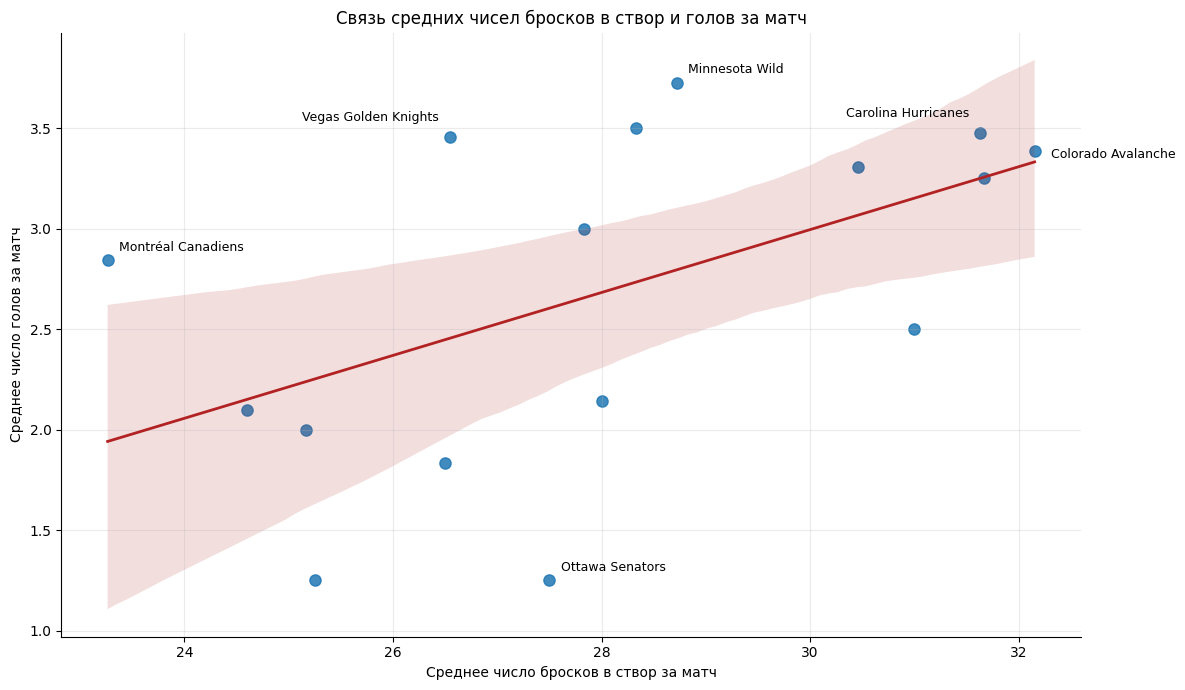

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 7))

sns.regplot(
    data=avgshots, x="Shot", y="Goal",
    ci=95,  # доверительная полоса регрессии 95%
    scatter_kws={"s": 65, "alpha": 0.85},
    line_kws={"color": "firebrick", "linewidth": 2},
    ax=ax,
)

label_offsets = {
    "Carolina Hurricanes": (-8, 12),
    "Colorado Avalanche": (12, -5),
    "Minnesota Wild": (8, 7),
    "Montréal Canadiens": (8, 7),
    "Ottawa Senators": (8, 7),
    "Vegas Golden Knights": (-8, 12),
}
for team, offset in label_offsets.items():
    row = avgshots.loc[team]
    ax.annotate(
        team, xy=(row["Shot"], row["Goal"]), xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left", fontsize=9,
    )

ax.set_title("Связь средних чисел бросков в створ и голов за матч")
ax.set_xlabel("Среднее число бросков в створ за матч")
ax.set_ylabel("Среднее число голов за матч")
ax.grid(alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [96]:
assert len(avgshots) == 16
assert avgshots[["Shot", "Goal"]].notna().all().all()

In [97]:
from scipy import stats

r, p_r = stats.pearsonr(avgshots["Shot"], avgshots["Goal"])
rho, p_rho = stats.spearmanr(avgshots["Shot"], avgshots["Goal"])
lr = stats.linregress(avgshots["Shot"], avgshots["Goal"])
t_crit = stats.t.ppf(0.975, df=len(avgshots) - 2)

print(f"Pearson r = {r:.3f}, p = {p_r:.3f}")
print(f"Spearman rho = {rho:.3f}, p = {p_rho:.3f}")
print(f"Наклон: {lr.slope:.3f} гола на 1 бросок в створ;"
      f" 95% ДИ [{lr.slope - t_crit*lr.stderr:.3f}; {lr.slope + t_crit*lr.stderr:.3f}]")
print(f"R² = {r**2:.3f}")

Pearson r = 0.521, p = 0.039
Spearman rho = 0.578, p = 0.019
Наклон: 0.156 гола на 1 бросок в створ; 95% ДИ [0.009; 0.303]
R² = 0.271


### Ответ на вопрос

Связь между средним числом бросков в створ и средним числом голов видна
и статистически значима на уровне 5%.

### Вывод

Связь положительная: r = 0,52 (p ≈ 0,04), ранговая корреляция Спирмена
ρ = 0,58 (p ≈ 0,02). Наклон регрессии 0,16: каждый дополнительный бросок
в створ за матч связан примерно с 0,16 гола за матч (95% ДИ от 0,01 до 0,30).
Число бросков в створ объясняет около 27% разброса средних значений голов
(R² = 0,27). Связь умеренная, а не сильная.

### Ограничения

- Точек всего 16, и каждая — среднее по команде. Команды сыграли разное число
  матчей (от 4 до 22), поэтому средние имеют разную точность.
- Это данные по командам, а не по матчам: выводы о конкретных играх делать нельзя.
- Связь не причинная. Команды, которые чаще бросают, могут быть сильнее и по
  другим причинам.

## Задача 14

In [60]:
all_shot_types = [
    "shot-on-goal",
    "goal",
    "missed-shot",
    "blocked-shot"
]

all_shot_mask = events["Play Type"].isin(all_shot_types)

shots_per_game = (
    events.loc[all_shot_mask]
    .groupby("Game ID")
    .size()
    .reindex(games.index, fill_value=0)
    .rename("Shot Count")
)

max_shot_count = shots_per_game.max()

max_shot_game_ids = shots_per_game.index[
    shots_per_game.eq(max_shot_count)
]

idxmax = shots_per_game.idxmax()

most_shots_games = shots_per_game.loc[max_shot_game_ids].to_frame()

most_shots_games.insert(
    0,
    "Game Info",
    [gameInfo(game_id) for game_id in most_shots_games.index]
)

In [61]:
assert shots_per_game.sum() == int(all_shot_mask.sum())
assert shots_per_game.index.equals(games.index)
assert idxmax in max_shot_game_ids

print("Максимальное число бросков в матче:", max_shot_count)
print("Число матчей с таким результатом:", len(max_shot_game_ids))
print(gameInfo(idxmax))

with pd.option_context("display.max_colwidth", None):
    display(most_shots_games)

Максимальное число бросков в матче: 208
Число матчей с таким результатом: 1
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


,Game Info,Shot Count
Game ID,,
2025030132,"Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)",208


In [62]:
shot_type_counts = (
    events.loc[
        events["Game ID"].eq(idxmax) & all_shot_mask,
        "Play Type"
    ]
    .value_counts()
    .reindex(all_shot_types, fill_value=0)
    .rename_axis("Play Type")
    .rename("Shot Count")
)

display(shot_type_counts.to_frame())

assert shot_type_counts.sum() == max_shot_count
print("Всего:", shot_type_counts.sum())

,Shot Count
Play Type,
shot-on-goal,83
goal,5
missed-shot,66
blocked-shot,54


Всего: 208


### Вывод

Матч с максимальным числом бросков найден:
Carolina Hurricanes — Ottawa Senators, 208 попыток.
Максимум достигнут в одном матче. Его идентификатор
2025030132 сохранён в переменной `idxmax` для следующей задачи.

## Задача 15

Построим карту всех бросков матча Carolina Hurricanes —
Ottawa Senators, найденного в задаче 14.

Цвет точки будет обозначать исход броска, форма маркера — команду.

Приведём направления атак к единому виду:
- гости Ottawa Senators атакуют левые ворота;
- хозяева Carolina Hurricanes атакуют правые ворота.

Для этого в нечётных периодах преобразуем координаты:
(x, y) → (−x, −y).

В чётных периодах координаты оставим без изменений.
Для изображения площадки используем приложенный файл `rink.py`.

In [63]:
from pathlib import Path
from google.colab import files

if not Path("rink.py").is_file():
    files.upload()

if not Path("rink.py").is_file():
    raise FileNotFoundError("Загрузите исходный файл с именем rink.py.")

from rink import plot_rink

Saving rink.py to rink.py


In [64]:
import numpy as np

match_shots = events.loc[
    events["Game ID"].eq(idxmax)
    & events["Play Type"].isin(all_shot_types)
].copy()

x_col = "X Coordinate on the Ice Rink"
y_col = "Y Coordinate on the Ice Rink"

assert len(match_shots) == max_shot_count == 208
assert match_shots[[x_col, y_col]].notna().all().all()

match_shots["Plot X"] = match_shots[x_col]
match_shots["Plot Y"] = match_shots[y_col]

odd_period = match_shots["Period"].mod(2).eq(1)

match_shots.loc[odd_period, "Plot X"] = (
    -match_shots.loc[odd_period, x_col]
)

match_shots.loc[odd_period, "Plot Y"] = (
    -match_shots.loc[odd_period, y_col]
)

side = match_shots["Home Team's Defending Side"]
assert side.isin(["left", "right"]).all()

home_attack_x = np.where(side.eq("left"), 89, -89)

normalized_home_attack_x = np.where(
    odd_period,
    -home_attack_x,
    home_attack_x
)

assert (normalized_home_attack_x == 89).all()

home_team = games.loc[idxmax, "Home Team"]
away_team = games.loc[idxmax, "Away Team"]

print(gameInfo(idxmax))
print("Число бросков:", len(match_shots))
print("Влево атакуют:", away_team)
print("Вправо атакуют:", home_team)

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Число бросков: 208
Влево атакуют: Ottawa Senators
Вправо атакуют: Carolina Hurricanes


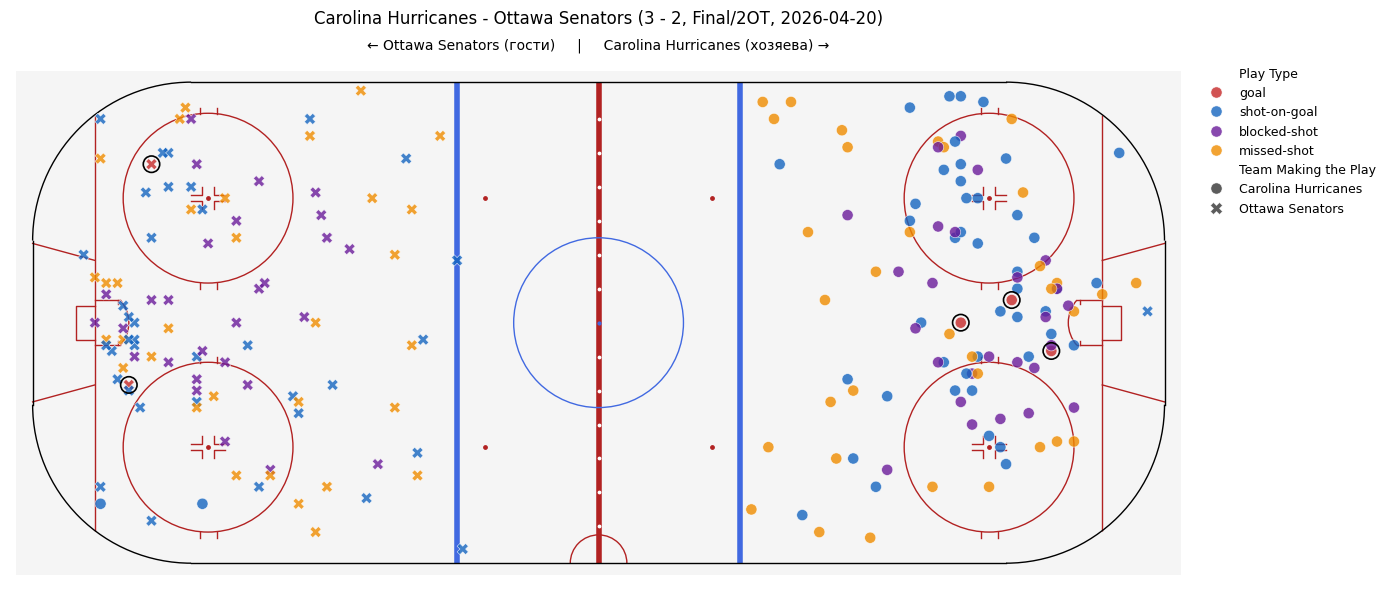

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 6.5))

plt.sca(ax)
plot_rink()

outcome_order = [
    "goal",
    "shot-on-goal",
    "blocked-shot",
    "missed-shot"
]

outcome_colors = {
    "goal": "#C62828",
    "shot-on-goal": "#1565C0",
    "blocked-shot": "#6A1B9A",
    "missed-shot": "#EF8C00"
}

sns.scatterplot(
    data=match_shots,
    x="Plot X",
    y="Plot Y",
    hue="Play Type",
    hue_order=outcome_order,
    palette=outcome_colors,
    style="Team Making the Play",
    style_order=[home_team, away_team],
    markers={home_team: "o", away_team: "X"},
    s=65,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.45,
    zorder=3,
    ax=ax
)

goal_points = match_shots.loc[
    match_shots["Play Type"].eq("goal")
]

ax.scatter(
    goal_points["Plot X"],
    goal_points["Plot Y"],
    s=140,
    facecolors="none",
    edgecolors="black",
    linewidths=1.2,
    zorder=4
)

ax.set_title(gameInfo(idxmax), fontsize=12, pad=28)

ax.text(
    0.5, 1.025,
    f"← {away_team} (гости)     |     {home_team} (хозяева) →",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.set_xlim(-104, 104)
ax.set_ylim(-46, 46)

ax.set_aspect("equal", adjustable="box")
ax.set_axis_off()

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    frameon=False,
    fontsize=9
)

plt.tight_layout()
plt.show()

### Преобразование координат

В выбранном матче направления атак менялись между периодами.
Для сопоставимости бросков выполнен поворот координат
в нечётных периодах 1, 3 и 5.

После преобразования Ottawa Senators атакуют левые ворота,
а Carolina Hurricanes — правые во всех периодах.

Это не означает, что все броски команды должны находиться
на одной половине площадки: возможны и дальние попытки.

### Интерпретация графика
На площадку нанесены все 208 бросков, включая 5 голов.
Некоторые точки могут перекрываться, поэтому визуально
различимых маркеров может быть меньше числа событий.

Основная масса бросков каждой команды расположена ближе
к атакуемым воротам, но встречаются и дальние попытки.

Цвет позволяет различить исходы бросков, форма маркера —
команды. Голы дополнительно выделены чёрной обводкой:
три у Carolina Hurricanes и два у Ottawa Senators.

### Вывод

Построена карта бросков выбранного матча с единым направлением
атаки для каждой команды.

Преобразованные координаты сохранены в столбцах `Plot X`
и `Plot Y` вспомогательной таблицы `match_shots`.
Исходные координаты и рассчитанные ранее расстояния не изменены.

Диаграмма показывает расположение и исходы бросков,
но сама по себе не оценивает вероятность гола из каждой точки.

## Задача 16

In [66]:
goal_events = events.loc[
    events["Play Type"].eq("goal")
].copy()

assert goal_events["Player in the Event #1"].notna().all()

player_goals = (
    goal_events.groupby("Player in the Event #1")
    .size()
    .rename("Goals")
)

player_goals.index.name = "Player"

goal_ranking = (
    player_goals.reset_index()
    .sort_values(
        ["Goals", "Player"],
        ascending=[False, True]
    )
    .set_index("Player")
)

top10_scorers = goal_ranking.head(10)

display(top10_scorers)

,Goals
Player,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Alex Newhook,7
Jackson Blake,7
Mark Stone,7


In [67]:
# Каждый гол должен быть учтён ровно один раз.
assert player_goals.sum() == len(goal_events) == 486
assert len(top10_scorers) == 10
assert top10_scorers["Goals"].is_monotonic_decreasing

print("Всего учтено голов:", player_goals.sum())

cutoff_goals = top10_scorers["Goals"].iloc[-1]

cutoff_players = goal_ranking.loc[
    goal_ranking["Goals"].eq(cutoff_goals)
]

print("Число голов у десятого игрока:", cutoff_goals)
print("Все игроки с таким числом голов:")

display(cutoff_players)

Всего учтено голов: 486
Число голов у десятого игрока: 7
Все игроки с таким числом голов:


,Goals
Player,
Alex Newhook,7
Jackson Blake,7
Mark Stone,7
Matt Boldy,7
Nathan MacKinnon,7
Taylor Hall,7


### Вывод

Лидер по числу голов — Brett Howden, 14 голов.

Создан полный рейтинг `goal_ranking` и список десяти игроков
`top10_scorers`. Учтены все 486 голов.

Количество голов каждого игрока сохранено в `player_goals`
для использования в последующих задачах.

## Задача 17

In [68]:
goal_events = events.loc[
    events["Play Type"].eq("goal")
].copy()

assist_columns = [
    "Player in the Event #2",
    "Player in the Event #3"
]

assists_long = goal_events[assist_columns].melt(
    value_vars=assist_columns,
    var_name="Assist Position",
    value_name="Player"
)

assists_long = assists_long.dropna(subset=["Player"])

player_assists = (
    assists_long.groupby("Player")
    .size()
    .rename("Assists")
)

assist_ranking = (
    player_assists.reset_index()
    .sort_values(
        ["Assists", "Player"],
        ascending=[False, True]
    )
    .set_index("Player")
)

top10_assists = assist_ranking.head(10)

display(top10_assists)

,Assists
Player,
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Taylor Hall,12
Kirill Kaprizov,11


In [69]:
expected_assists = goal_events[assist_columns].notna().sum().sum()

assert player_assists.sum() == expected_assists == len(assists_long)
assert len(top10_assists) == 10
assert top10_assists["Assists"].is_monotonic_decreasing

both_assists = goal_events[assist_columns].dropna()

assert both_assists[assist_columns[0]].ne(
    both_assists[assist_columns[1]]
).all()

print("Всего голов:", len(goal_events))
print("Всего учтено голевых передач:", player_assists.sum())

assist_cutoff = top10_assists["Assists"].iloc[-1]

assist_cutoff_players = assist_ranking.loc[
    assist_ranking["Assists"].eq(assist_cutoff)
]

print("Число передач у десятого игрока:", assist_cutoff)
print("Все игроки с таким числом передач:")

display(assist_cutoff_players)

Всего голов: 486
Всего учтено голевых передач: 830
Число передач у десятого игрока: 11
Все игроки с таким числом передач:


,Assists
Player,
Kirill Kaprizov,11
Quinn Hughes,11


### Метод расчёта

Имена из двух столбцов ассистентов объединены в один столбец
с помощью `melt()`. После удаления пропусков подсчитано
количество упоминаний каждого игрока.

Повторные упоминания одного игрока в разных голах сохранены,
поскольку каждое соответствует отдельной голевой передаче.

### Вывод

Создан полный рейтинг `assist_ranking` и список десяти игроков
`top10_assists`. Лидер рейтинга — Jack Eichel.

Число передач каждого игрока сохранено в `player_assists`.
В следующей задаче используем его для расчёта очков
по системе «гол + пас».

## Задача 18

Выведем десять игроков, набравших больше всего очков
по системе «гол + пас».

За каждый гол и каждую голевую передачу начисляется одно очко.
Используем `player_goals` из задачи 16 и `player_assists`
из задачи 17.

При одинаковом числе очков используем алфавитный порядок имён.

In [70]:
player_points = pd.concat(
    [player_goals, player_assists],
    axis=1,
    join="outer"
).fillna(0).astype(int)

player_points.index.name = "Player"

player_points["Points"] = (
    player_points["Goals"] + player_points["Assists"]
)

points_ranking = (
    player_points.reset_index()
    .sort_values(
        ["Points", "Player"],
        ascending=[False, True]
    )
    .set_index("Player")
)

top10_points = points_ranking.head(10)

display(top10_points)

,Goals,Assists,Points
Player,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Lane Hutson,3,13,16
Logan Stankoven,11,5,16


In [71]:
assert set(player_points.index) == (
    set(player_goals.index) | set(player_assists.index)
)
assert player_points.index.is_unique

assert player_points["Goals"].sum() == player_goals.sum() == 486
assert player_points["Assists"].sum() == player_assists.sum() == 830
assert player_points["Points"].sum() == 1316
assert len(top10_points) == 10
assert top10_points["Points"].is_monotonic_decreasing

print("Всего учтено очков:", player_points["Points"].sum())

points_cutoff = top10_points["Points"].iloc[-1]

points_cutoff_players = points_ranking.loc[
    points_ranking["Points"].eq(points_cutoff)
]

print("Очки десятого игрока:", points_cutoff)
display(points_cutoff_players)

Всего учтено очков: 1316
Очки десятого игрока: 16


,Goals,Assists,Points
Player,,,
Lane Hutson,3,13,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16
Pavel Dorofeyev,12,4,16


### Вывод

Больше всего очков набрал Mitch Marner — 29
(10 голов и 19 передач). Далее следуют Jack Eichel
с 22 очками и Jackson Blake с 20 очками.
На границе десятки четыре игрока имеют по 16 очков.
По принятому алфавитному правилу включены Lane Hutson,
Logan Stankoven и Nick Suzuki. Pavel Dorofeyev имеет
такой же результат, но не вошёл в список из ровно десяти игроков.
Рейтинг отражает суммарные очки за плей-офф,
а не среднее число за матч.

## Задача 19

Выведем десять игроков, которые в среднем совершили больше всего
бросков в створ за матч.

In [72]:
appearance_columns = (
    [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
    + [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
    + ["Away Team's Goalie", "Home Team's Goalie"]
)

player_appearances = (
    events[["Game ID"] + appearance_columns]
    .melt(
        id_vars="Game ID",
        value_vars=appearance_columns,
        value_name="Player"
    )
    .dropna(subset=["Player"])
    .drop_duplicates(subset=["Game ID", "Player"])
)

player_games = (
    player_appearances.groupby("Player")["Game ID"]
    .nunique()
    .rename("Games Played")
)

In [73]:
player_shot_events = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal"]),
    ["Game ID", "Player in the Event #1"]
].copy()

assert player_shot_events["Player in the Event #1"].notna().all()

player_shots_on_goal = (
    player_shot_events.groupby("Player in the Event #1")
    .size()
    .rename("Shots on Goal")
)
player_shots_on_goal.index.name = "Player"

player_shot_stats = player_games.to_frame().join(player_shots_on_goal)

player_shot_stats["Shots on Goal"] = (
    player_shot_stats["Shots on Goal"].fillna(0).astype(int)
)

player_shot_stats["Shots per Game"] = (
    player_shot_stats["Shots on Goal"]
    / player_shot_stats["Games Played"]
)

player_shot_ranking = (
    player_shot_stats.reset_index()
    .sort_values(
        ["Shots per Game", "Player"],
        ascending=[False, True]
    )
    .set_index("Player")
)

top10_shots_per_game = player_shot_ranking.head(10)

with pd.option_context("display.float_format", "{:.3f}".format):
    display(top10_shots_per_game)

,Games Played,Shots on Goal,Shots per Game
Player,,,
Jason Robertson,6,30,5.000
Dylan Guenther,6,27,4.500
Nikita Kucherov,7,31,4.429
Matt Boldy,11,48,4.364
Quinton Byfield,4,17,4.250
Darren Raddysh,7,28,4.000
Joel Eriksson Ek,6,24,4.000
Alex Laferriere,4,15,3.750
David Pastrnak,6,22,3.667


In [74]:
assert set(player_shots_on_goal.index).issubset(player_games.index)
assert player_games.gt(0).all()

shot_pairs = pd.MultiIndex.from_frame(
    player_shot_events.rename(
        columns={"Player in the Event #1": "Player"}
    )[["Game ID", "Player"]]
)

appearance_pairs = pd.MultiIndex.from_frame(
    player_appearances[["Game ID", "Player"]]
)

assert shot_pairs.isin(appearance_pairs).all()

assert player_shot_stats["Shots on Goal"].sum() == len(player_shot_events) == 4623
assert len(top10_shots_per_game) == 10
assert top10_shots_per_game["Shots per Game"].is_monotonic_decreasing

print("Всего учтено бросков в створ:", len(player_shot_events))

shot_rate_cutoff = top10_shots_per_game["Shots per Game"].iloc[-1]

shot_rate_cutoff_players = player_shot_ranking.loc[
    player_shot_ranking["Shots per Game"].eq(shot_rate_cutoff)
]

print(f"Среднее у десятого игрока: {shot_rate_cutoff:.3f}")

with pd.option_context("display.float_format", "{:.3f}".format):
    display(shot_rate_cutoff_players)

Всего учтено бросков в створ: 4623
Среднее у десятого игрока: 3.615


,Games Played,Shots on Goal,Shots per Game
Player,,,
Nathan MacKinnon,13,47,3.615


### Вывод

Наибольшее среднее число бросков в створ у Jason Robertson:
30 бросков за 6 матчей, или 5 за матч.
Далее следуют Dylan Guenther — 4,500 и Nikita Kucherov —
около 4,429 броска за матч.

В расчёт включены голы и все матчи участия игроков,
в том числе матчи без бросков. Число сыгранных матчей показано
в таблице, поскольку объём наблюдений у игроков различается.

## Задача 20

Выведем десять игроков с наибольшим средним числом
силовых приёмов за матч.

Используем события `hit`. Игрок, выполнивший силовой приём,
указан в поле `Player in the Event #1`.

In [75]:
hit_events = events.loc[
    events["Play Type"].eq("hit"),
    ["Game ID", "Player in the Event #1"]
].copy()

assert hit_events["Player in the Event #1"].notna().all()

player_hits = (
    hit_events.groupby("Player in the Event #1")
    .size()
    .rename("Hits")
)
player_hits.index.name = "Player"

player_hit_stats = player_games.to_frame().join(player_hits)

player_hit_stats["Hits"] = (
    player_hit_stats["Hits"].fillna(0).astype(int)
)

player_hit_stats["Hits per Game"] = (
    player_hit_stats["Hits"]
    / player_hit_stats["Games Played"]
)

player_hit_ranking = (
    player_hit_stats.reset_index()
    .sort_values(
        ["Hits per Game", "Player"],
        ascending=[False, True]
    )
    .set_index("Player")
)

top10_hits_per_game = player_hit_ranking.head(10)

with pd.option_context("display.float_format", "{:.3f}".format):
    display(top10_hits_per_game)

,Games Played,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38,6.333
Alex Turcotte,1,6,6.000
Alexander Petrovic,1,6,6.000
Yakov Trenin,9,51,5.667
Dylan Cozens,4,22,5.500
Vasily Podkolzin,6,32,5.333
Carl Grundstrom,3,15,5.000
Ivan Barbashev,22,110,5.000
Marcus Foligno,11,55,5.000


In [76]:
assert set(player_hits.index).issubset(player_games.index)
assert player_games.gt(0).all()

assert player_hit_stats["Hits"].sum() == len(hit_events)
assert len(top10_hits_per_game) == 10
assert top10_hits_per_game["Hits per Game"].is_monotonic_decreasing

print("Всего учтено силовых приёмов:", len(hit_events))

hit_rate_cutoff = top10_hits_per_game["Hits per Game"].iloc[-1]

hit_rate_cutoff_players = player_hit_ranking.loc[
    player_hit_ranking["Hits per Game"].eq(hit_rate_cutoff)
]

print(f"Среднее у десятого игрока: {hit_rate_cutoff:.3f}")

with pd.option_context("display.float_format", "{:.3f}".format):
    display(hit_rate_cutoff_players)

Всего учтено силовых приёмов: 5621
Среднее у десятого игрока: 4.833


,Games Played,Hits,Hits per Game
Player,,,
Owen Tippett,6,29,4.833


### Вывод

Наибольшее среднее число силовых приёмов у Lawson Crouse:
38 приёмов за 6 матчей, или около 6,333 за матч.
Alex Turcotte и Alexander Petrovic имеют по 6 приёмов за матч,
но каждый участвовал только в одном матче. Поэтому их средние
рассчитаны по меньшему объёму данных.
Учтены все матчи участия, включая матчи без силовых приёмов.
Минимальный порог по числу матчей не вводился,
поскольку он не задан условием.

## Задача 21

In [78]:
away_goalies = events[
    ["Game ID", "Away Team", "Away Team's Goalie"]
].rename(columns={
    "Away Team": "Team",
    "Away Team's Goalie": "Goalie"
})

home_goalies = events[
    ["Game ID", "Home Team", "Home Team's Goalie"]
].rename(columns={
    "Home Team": "Team",
    "Home Team's Goalie": "Goalie"
})

goalie_appearances = (
    pd.concat([away_goalies, home_goalies], ignore_index=True)
    .dropna(subset=["Goalie"])
    .drop_duplicates(subset=["Game ID", "Team", "Goalie"])
)

goalie_game_stats = goalie_appearances.set_index(
    ["Game ID", "Team", "Goalie"]
).sort_index()

In [79]:
goal_events = events.loc[
    events["Play Type"].eq("goal")
].copy()

home_scored = goal_events["Team Making the Play"].eq(
    goal_events["Home Team"]
)
away_scored = goal_events["Team Making the Play"].eq(
    goal_events["Away Team"]
)

assert (home_scored | away_scored).all()

conceded_events = pd.DataFrame({
    "Game ID": goal_events["Game ID"],

    "Team": goal_events["Away Team"].where(
        home_scored,
        goal_events["Home Team"]
    ),

    "Goalie": goal_events["Away Team's Goalie"].where(
        home_scored,
        goal_events["Home Team's Goalie"]
    )
})

empty_net_goals = conceded_events["Goalie"].isna().sum()

goals_against = (
    conceded_events.dropna(subset=["Goalie"])
    .groupby(["Game ID", "Team", "Goalie"])
    .size()
    .rename("Goals Against")
)

goalie_game_stats = goalie_game_stats.join(goals_against)

goalie_game_stats["Goals Against"] = (
    goalie_game_stats["Goals Against"].fillna(0).astype(int)
)

goalie_zero_games = goalie_game_stats.loc[
    goalie_game_stats["Goals Against"].eq(0)
].copy()

zero_goalies = (
    goalie_zero_games.index.get_level_values("Goalie")
    .unique()
    .sort_values()
)

print("Вратари без пропущенных голов хотя бы в одном матче участия:")

for goalie in zero_goalies:
    print(goalie)

print("Всего вратарей:", len(zero_goalies))

Вратари без пропущенных голов хотя бы в одном матче участия:
Andrei Vasilevskiy
Arturs Silovs
Brandon Bussi
Dan Vladar
Frederik Andersen
Jakub Dobes
Joonas Korpisalo
Scott Wedgewood
Всего вратарей: 8


In [80]:
assert goals_against.index.isin(goalie_game_stats.index).all()
assert goalie_game_stats.index.is_unique
assert goalie_game_stats["Goals Against"].ge(0).all()

assert (
    goalie_game_stats["Goals Against"].sum() + empty_net_goals
    == len(goal_events)
)

goalie_zero_details = goalie_zero_games.reset_index()

goalie_zero_details["Game Info"] = (
    goalie_zero_details["Game ID"].map(gameInfo)
)

goalie_zero_details = goalie_zero_details[[
    "Goalie",
    "Game ID",
    "Team",
    "Goals Against",
    "Game Info"
]].sort_values(["Goalie", "Game ID"])

with pd.option_context("display.max_colwidth", None):
    display(goalie_zero_details)

print(
    "Матчей участия вратарей без пропущенных голов:",
    len(goalie_zero_games)
)
print("Голов в пустые ворота:", empty_net_goals)

,Goalie,Game ID,Team,Goals Against,Game Info
2,Andrei Vasilevskiy,2025030126,Tampa Bay Lightning,0,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)"
6,Arturs Silovs,2025030146,Pittsburgh Penguins,0,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)"
10,Brandon Bussi,2025030413,Carolina Hurricanes,0,"Vegas Golden Knights - Carolina Hurricanes (5 - 4, Final/2OT, 2026-06-06)"
11,Brandon Bussi,2025030416,Carolina Hurricanes,0,"Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)"
4,Dan Vladar,2025030142,Philadelphia Flyers,0,"Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)"
5,Dan Vladar,2025030146,Philadelphia Flyers,0,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)"
3,Frederik Andersen,2025030131,Carolina Hurricanes,0,"Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)"
7,Frederik Andersen,2025030221,Carolina Hurricanes,0,"Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)"
9,Frederik Andersen,2025030314,Carolina Hurricanes,0,"Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)"
1,Jakub Dobes,2025030126,Montréal Canadiens,0,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)"


Матчей участия вратарей без пропущенных голов: 12
Голов в пустые ворота: 25


### Вывод

Найдено 8 вратарей, которые хотя бы в одном матче
не пропустили шайб за время своего нахождения на льду.
Всего таких случаев участия — 12.

Включены неполные матчи, как требует условие.
Поэтому команда могла пропустить голы, но конкретный вратарь
всё равно попасть в список, если эти голы пришлись
на время отсутствия его на льду.

Голы в пустые ворота не включены в индивидуальные
пропущенные голы вратарей.

## Задача 22

Вопрос: побеждает ли чаще команда, которая нанесла больше бросков в створ,
чем её соперник?

Бросок в створ — это `shot-on-goal` или `goal`, то есть показатель из таблицы `numshots`.
Матчи, в которых команды нанесли одинаковое число бросков в створ, в расчёт доли не входят.

In [86]:
import numpy as np
import pandas as pd

match_table = games[["Away Team", "Home Team", "Away Score", "Home Score"]].copy()

for side in ["Away", "Home"]:
    team_index = pd.MultiIndex.from_arrays(
        [games.index, games[f"{side} Team"]],
        names=["Game ID", "Team Making the Play"]
    )
    match_table[f"{side} Shots"] = (
        numshots["Shots on Goal"].reindex(team_index).to_numpy()
    )

home_won = match_table["Home Score"] > match_table["Away Score"]

match_table["Winner Shots"] = np.where(home_won, match_table["Home Shots"], match_table["Away Shots"])
match_table["Loser Shots"] = np.where(home_won, match_table["Away Shots"], match_table["Home Shots"])
match_table["Shot Diff"] = match_table["Winner Shots"] - match_table["Loser Shots"]

# Проверки
assert len(match_table) == 82
assert match_table[["Away Shots", "Home Shots"]].notna().all().all()
assert match_table["Away Score"].ne(match_table["Home Score"]).all()
assert match_table[["Away Shots", "Home Shots"]].sum().sum() == 4623

print("Матчей:", len(match_table))

Матчей: 82


In [87]:
decisive = match_table[match_table["Shot Diff"] != 0]
n_decisive = len(decisive)
n_more_wins = int((decisive["Shot Diff"] > 0).sum())
n_fewer_wins = int((decisive["Shot Diff"] < 0).sum())
n_ties = int((match_table["Shot Diff"] == 0).sum())

assert n_decisive + n_ties == 82
assert n_more_wins + n_fewer_wins == n_decisive

summary = pd.DataFrame(
    {"Число матчей": [n_more_wins, n_fewer_wins, n_ties]},
    index=[
        "Победила команда с большим числом бросков",
        "Победила команда с меньшим числом бросков",
        "Равное число бросков в створ",
    ],
)
summary["Доля всех матчей, %"] = (100 * summary["Число матчей"] / 82).round(2)
display(summary)

print(f"Матчей без равенства бросков: {n_decisive}")
print(f"Доля побед команды с большим числом бросков: {n_more_wins / n_decisive:.2%}")

,Число матчей,"Доля всех матчей, %"
Победила команда с большим числом бросков,47,57.32
Победила команда с меньшим числом бросков,31,37.80
Равное число бросков в створ,4,4.88


Матчей без равенства бросков: 78
Доля побед команды с большим числом бросков: 60.26%


In [88]:
from scipy.stats import binomtest

test_two = binomtest(n_more_wins, n_decisive, p=0.5, alternative="two-sided")
test_one = binomtest(n_more_wins, n_decisive, p=0.5, alternative="greater")
ci = test_two.proportion_ci(confidence_level=0.95, method="exact")

print(f"Доля побед: {n_more_wins / n_decisive:.3f}")
print(f"95% доверительный интервал (точный): [{ci.low:.3f}; {ci.high:.3f}]")
print(f"p-value, двусторонний (основной результат): {test_two.pvalue:.3f}")
print(f"p-value, односторонний (дополнение): {test_one.pvalue:.3f}")

Доля побед: 0.603
95% доверительный интервал (точный): [0.485; 0.712]
p-value, двусторонний (основной результат): 0.089
p-value, односторонний (дополнение): 0.044


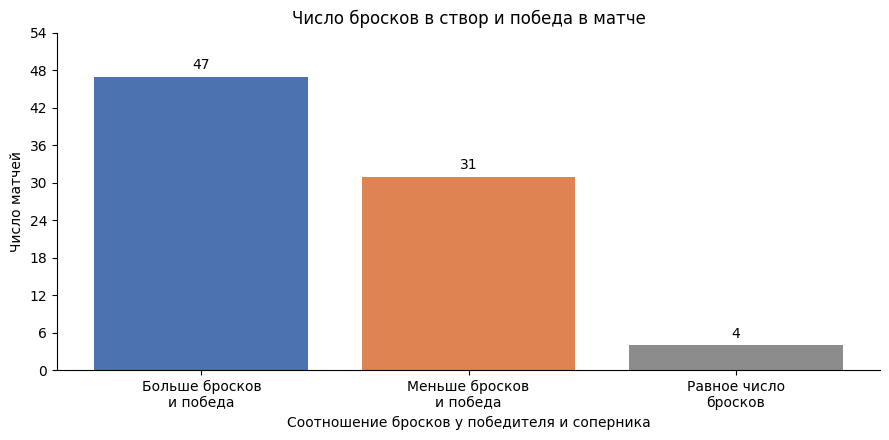

In [89]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

labels = [
    "Больше бросков\nи победа",
    "Меньше бросков\nи победа",
    "Равное число\nбросков",
]
values = [n_more_wins, n_fewer_wins, n_ties]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, values, color=["#4C72B0", "#DD8452", "#8C8C8C"])
ax.bar_label(bars, padding=3)

ax.set_title("Число бросков в створ и победа в матче")
ax.set_xlabel("Соотношение бросков у победителя и соперника")
ax.set_ylabel("Число матчей")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

### Ответ на исследовательский вопрос

В 47 из 78 матчей, где число бросков в створ различалось, победила команда,
которая бросала в створ чаще, — это 60,3% матчей. 95%-й доверительный интервал
для доли побед: примерно от 48,5% до 71,2%.

Основной результат — двусторонний тест: p = 0,089. На уровне значимости 5%
связь между числом бросков и победой статистически не подтверждена. Есть тенденция:
доля побед больше половины, но данных для уверенного вывода недостаточно.
Односторонний тест (p = 0,044) приведён как дополнение; он проверяет более узкую
гипотезу «побеждают чаще, чем в половине матчей» и не заменяет основной вывод.

### Ограничения

- Бросок в створ не отражает качество моментов: дальний бросок и бросок с пятачка
  учитываются одинаково.
- Число бросков может быть следствием игры, а не её причиной: команда, которая
  ведёт, часто меньше атакует, а проигрывающая — чаще бросает, пытаясь отыграться.
- Матчи не независимы: одни и те же команды встречаются в серии несколько раз.
- Четыре матча с равным числом бросков в расчёт доли не включены.